# Laser Particles as a Physical Reservoir

Goal: test, in simulation, whether a single laser particle can work as a reservoir in reservoir computing. We compare it against a standard software reservoir, the Echo State Network (ESN), on the NARMA10 task.

Sections:
0. Task and score (NARMA10, NMSE)
1. ESN baseline

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## 0. Task and score

**NARMA10.** The input u(k) is random, drawn uniformly from [0, 0.5]. The target y(k) follows

y(k+1) = 0.3·y(k) + 0.05·y(k)·[y(k) + ... + y(k−9)] + 1.5·u(k−9)·u(k) + 0.1

To predict y(k+1), a model must remember inputs from 9 steps back (memory) and multiply terms together (nonlinearity).

**NMSE** (normalized mean squared error) = mean((prediction − target)²) / var(target). 0 is perfect. 1 is the same error as always predicting the mean of the target. Appeltant et al. report NRMSE = √NMSE.

In [2]:
def narma10(n_steps, seed):
    """Return input u and NARMA10 output y, each of length n_steps."""
    rng = np.random.default_rng(seed)
    u = rng.uniform(0, 0.5, n_steps)
    y = np.zeros(n_steps)
    for k in range(9, n_steps - 1):
        y[k + 1] = (0.3 * y[k]
                    + 0.05 * y[k] * np.sum(y[k - 9:k + 1])
                    + 1.5 * u[k - 9] * u[k]
                    + 0.1)
    # NARMA10 can blow up for unlucky inputs; stop here if it does
    assert np.all(np.isfinite(y)) and y.max() < 10, "NARMA10 diverged, try another seed"
    return u, y


def nmse(prediction, target):
    return np.mean((prediction - target) ** 2) / np.var(target)

**Alignment.** y(k+1) depends only on inputs up to u(k). So after the model has seen u(k), it is asked for y(k+1). We store this as a target sequence `d`, with d(k) = y(k+1).

**Split.** The first 200 steps are discarded (washout: the reservoir still depends on its zero starting state, and y is still settling from 0). The rest is split into train, validation and test. Settings are chosen on validation. Test is used only once, for the final score.

The same seed and split will be used for the laser reservoir, so both models see exactly the same data.

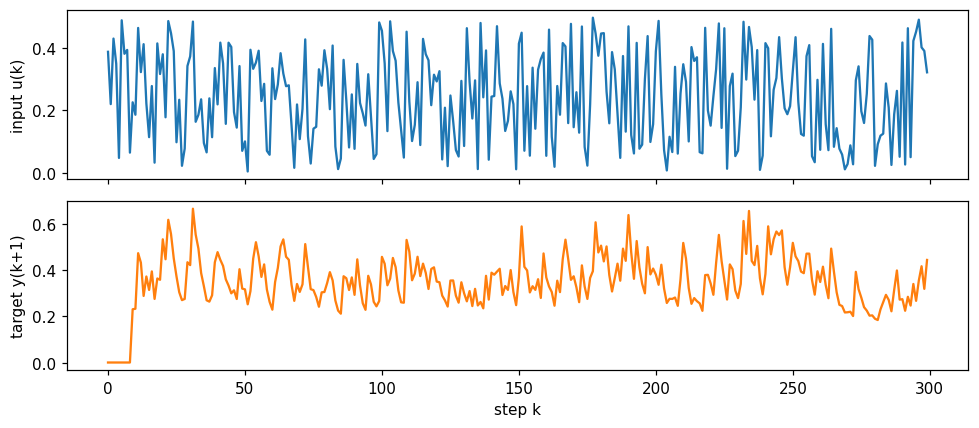

In [3]:
DATA_SEED = 42
WASHOUT, N_TRAIN, N_VAL, N_TEST = 200, 3000, 800, 1000
n_steps = WASHOUT + N_TRAIN + N_VAL + N_TEST

u_all, y_all = narma10(n_steps + 1, DATA_SEED)
u = u_all[:-1]   # input fed at step k
d = y_all[1:]    # target at step k is y(k+1)

train = slice(WASHOUT, WASHOUT + N_TRAIN)
val = slice(WASHOUT + N_TRAIN, WASHOUT + N_TRAIN + N_VAL)
test = slice(WASHOUT + N_TRAIN + N_VAL, n_steps)

fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(u[:300]); ax[0].set_ylabel("input u(k)")
ax[1].plot(d[:300], color="C1"); ax[1].set_ylabel("target y(k+1)")
ax[1].set_xlabel("step k")
plt.tight_layout(); plt.show()

## 1. Echo State Network (ESN) baseline

An ESN is a recurrent network whose internal weights are random and fixed. Only the output weights are trained.

State update, for N nodes:

x(k) = tanh( W·x(k−1) + W_in·u(k) + b )

- **W** (N×N): random recurrent weights. Sparse: about 10% of entries are nonzero.
- **Spectral radius ρ**: the largest absolute eigenvalue of W. We rescale W so it equals ρ < 1. With ρ < 1 the effect of old inputs shrinks over time, so the state depends on recent inputs only (fading memory).
- **W_in** (N values): random input weights, uniform in [−s, s]. The input scaling s sets how far the nodes are pushed into the curved part of tanh, i.e. how nonlinear they act.
- **b** (N values): random constant bias, so that different nodes sit at different points on the tanh curve.

**Readout.** The prediction is a weighted sum: ŷ(k) = W_out · [x(k), u(k), 1]. W_out is found by ridge regression, which is least squares plus a penalty α·|W_out|² that keeps weights small:

W_out = (FᵀF + αI)⁻¹ Fᵀd, where each row of F is [x(k), u(k), 1].

In [4]:
def make_esn(n_nodes, spectral_radius, input_scale, seed, density=0.1, bias_scale=0.1):
    rng = np.random.default_rng(seed)
    W = rng.uniform(-1, 1, (n_nodes, n_nodes))
    W *= rng.random((n_nodes, n_nodes)) < density   # keep ~10% of connections
    W *= spectral_radius / np.max(np.abs(np.linalg.eigvals(W)))
    W_in = rng.uniform(-input_scale, input_scale, n_nodes)
    b = rng.uniform(-bias_scale, bias_scale, n_nodes)
    return W, W_in, b


def run_esn(W, W_in, b, u):
    """Drive the ESN with input u. Return the state matrix, one row per step."""
    x = np.zeros(W.shape[0])
    states = np.zeros((len(u), W.shape[0]))
    for k in range(len(u)):
        x = np.tanh(W @ x + W_in * u[k] + b)
        states[k] = x
    return states


def features(states, u):
    """Readout features: reservoir state, raw input, and a constant 1."""
    return np.column_stack([states, u, np.ones(len(u))])


def train_readout(F, target, ridge):
    return np.linalg.solve(F.T @ F + ridge * np.eye(F.shape[1]), F.T @ target)

### 1.1 Choose ρ, s and α on the validation set

We try a small grid. Each setting is scored by the mean validation NMSE over 3 random reservoirs, because one random reservoir can be lucky or unlucky.

In [5]:
N_NODES = 100   # same as the "traditional RC" in Appeltant et al.

results = []
for rho in [0.8, 0.9, 0.95]:
    for s in [0.05, 0.1, 0.2]:
        # Ridge does not change the states, so run each reservoir once per (rho, s)
        Fs = [features(run_esn(*make_esn(N_NODES, rho, s, seed), u), u) for seed in range(3)]
        for ridge in [1e-8, 1e-6, 1e-4]:
            scores = [nmse(F[val] @ train_readout(F[train], d[train], ridge), d[val]) for F in Fs]
            results.append((np.mean(scores), rho, s, ridge))

results.sort()
print("Best 5 settings (validation NMSE, rho, s, ridge):")
for r in results[:5]:
    print(f"  {r[0]:.4f}   rho={r[1]}  s={r[2]}  ridge={r[3]:g}")
_, RHO, S_IN, RIDGE = results[0]

Best 5 settings (validation NMSE, rho, s, ridge):
  0.1106   rho=0.9  s=0.1  ridge=1e-08
  0.1176   rho=0.95  s=0.1  ridge=1e-08
  0.1178   rho=0.8  s=0.1  ridge=1e-08
  0.1184   rho=0.9  s=0.05  ridge=1e-08
  0.1186   rho=0.9  s=0.2  ridge=1e-08


### 1.2 Final score on the test set

We fix the chosen settings, train on train + validation together, and score on the test set. We repeat for 10 random reservoirs and report mean ± standard deviation.

In [6]:
train_val = slice(WASHOUT, WASHOUT + N_TRAIN + N_VAL)

test_scores = []
for seed in range(10):
    F = features(run_esn(*make_esn(N_NODES, RHO, S_IN, seed), u), u)
    W_out = train_readout(F[train_val], d[train_val], RIDGE)
    test_scores.append(nmse(F[test] @ W_out, d[test]))
    if seed == 0:
        esn_prediction = F[test] @ W_out

esn_nmse = np.mean(test_scores)
print(f"ESN test NMSE  = {esn_nmse:.4f} ± {np.std(test_scores):.4f}  (10 reservoirs)")
print(f"ESN test NRMSE = {np.sqrt(esn_nmse):.3f}")
print("Reference (Appeltant et al., as NMSE): shift register 0.16, traditional RC 0.032, delay reservoir 0.0225")

ESN test NMSE  = 0.0667 ± 0.0135  (10 reservoirs)
ESN test NRMSE = 0.258
Reference (Appeltant et al., as NMSE): shift register 0.16, traditional RC 0.032, delay reservoir 0.0225


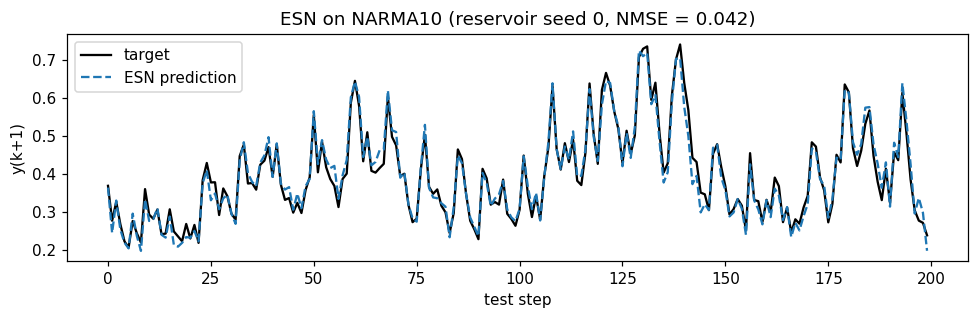

In [7]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(d[test][:200], label="target", color="k")
ax.plot(esn_prediction[:200], label="ESN prediction", color="C0", ls="--")
ax.set_xlabel("test step"); ax.set_ylabel("y(k+1)")
ax.set_title(f"ESN on NARMA10 (reservoir seed 0, NMSE = {test_scores[0]:.3f})")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the result.** An NMSE below 0.16 means the ESN does better than a memory-only model (the shift register in Appeltant et al.). So its nonlinearity is helping. Our ESN does not reach Appeltant's traditional-RC value (NMSE ≈ 0.032). Their reservoir design and training length are not fully specified, so we treat our value as the baseline for this notebook. The laser reservoir will be compared against this number, using the same data and split.